# Assignment 3 — Part A
## Sanjeevani Diagnostics: KNN classification and the HbA1c budget

### Q1 — Load the export as text

Read every field as text so identifiers, mixed formats, and the original target header are preserved before cleaning.

In [1]:
# Q1
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, roc_auc_score
)
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder

DATA_PATH = Path("raw_data/sanjeevani_diabetes_screening_raw.csv")
if not DATA_PATH.exists():
    DATA_PATH = Path("sanjeevani_diabetes_screening_raw.csv")

raw_a = pd.read_csv(DATA_PATH, dtype=str, keep_default_na=False)

print("Shape:", raw_a.shape)
print("Raw column names:")
for column_name in raw_a.columns:
    print(repr(column_name))

for column_name in ["Sex", "family_history", "HbA1c Result "]:
    print(f"\nDistinct values in {column_name!r}:")
    print(raw_a[column_name].value_counts(dropna=False).to_string())

Shape: (3038, 13)
Raw column names:
'Patient ID'
'Camp Location'
'Sex'
'Age'
'family_history'
'height_cm'
'weight_kg'
'BMI'
'waist_cm'
'Daily Steps'
'Blood Pressure'
'total_cholesterol'
'HbA1c Result '

Distinct values in 'Sex':
Sex
Male      1144
Female    1112
female     147
F          133
MALE       131
FEMALE     129
M          124
male       118

Distinct values in 'family_history':
family_history
N      530
No     511
0      499
no     478
Y      277
1      257
yes    248
Yes    238

Distinct values in 'HbA1c Result ':
HbA1c Result 
0           614
Negative    606
No          580
normal      553
DIABETIC    187
Positive    173
Yes         164
1           161


### Q2 — Standardise headers and categories

Header cleanup removes the trailing space from the target name. Location and sex values are mapped to one canonical spelling.

In [2]:
# Q2
a_work = raw_a.copy()
a_work.columns = (
    a_work.columns.str.strip()
    .str.lower()
    .str.replace(r"[^a-z0-9]+", "_", regex=True)
    .str.strip("_")
)

location_map = {
    "kharghar": "Kharghar",
    "panvel": "Panvel",
    "vashi": "Vashi",
    "nerul": "Nerul",
    "thane": "Thane",
    "dombivli": "Dombivli"
}
a_work["camp_location"] = (
    a_work["camp_location"].astype(str).str.strip().str.lower().map(location_map)
)
a_work["sex"] = (
    a_work["sex"].astype(str).str.strip().str.lower()
    .map({"m": "Male", "male": "Male", "f": "Female", "female": "Female"})
)

print("Standardised columns:", a_work.columns.tolist())
print("Camp locations:", sorted(a_work["camp_location"].dropna().unique()))
print("Sex values:", sorted(a_work["sex"].dropna().unique()))
print("Interpretation: locations now have six canonical names and sex has two.")

Standardised columns: ['patient_id', 'camp_location', 'sex', 'age', 'family_history', 'height_cm', 'weight_kg', 'bmi', 'waist_cm', 'daily_steps', 'blood_pressure', 'total_cholesterol', 'hba1c_result']
Camp locations: ['Dombivli', 'Kharghar', 'Nerul', 'Panvel', 'Thane', 'Vashi']
Sex values: ['Female', 'Male']
Interpretation: locations now have six canonical names and sex has two.


### Q3 — Encode the labels and remove exact duplicates

`family_history` and `hba1c_result` become binary values. Duplicate detection uses the original rows, so formatting changes cannot turn two different raw records into duplicates.

In [3]:
# Q3
binary_map = {
    "yes": 1, "y": 1, "1": 1,
    "no": 0, "n": 0, "0": 0
}
target_map = {
    "positive": 1, "yes": 1, "1": 1, "diabetic": 1,
    "negative": 0, "no": 0, "0": 0, "normal": 0
}

a_work["family_history"] = (
    a_work["family_history"].astype(str).str.strip().str.lower().map(binary_map)
)
a_work["hba1c_result"] = (
    a_work["hba1c_result"].astype(str).str.strip().str.lower().map(target_map)
)

positive_rate_before_dedup = a_work["hba1c_result"].mean()
duplicate_mask_a = raw_a.duplicated(keep="first")
duplicates_a = int(duplicate_mask_a.sum())
rows_before_dedup_a = len(a_work)
a_work = a_work.loc[~duplicate_mask_a].copy()

print(f"Positive share before duplicate removal: {positive_rate_before_dedup:.2%}")
print(f"Exact duplicate rows removed: {duplicates_a}")
print(f"Rows before: {rows_before_dedup_a:,}; rows after: {len(a_work):,}")
print(f"Positive share after duplicate removal: {a_work['hba1c_result'].mean():.2%}")
print("Interpretation: the modelling table contains one copy of each original record.")

Positive share before duplicate removal: 22.55%
Exact duplicate rows removed: 38
Rows before: 3,038; rows after: 3,000
Positive share after duplicate removal: 22.63%
Interpretation: the modelling table contains one copy of each original record.


### Q4 — Convert measurements and split blood pressure

Numeric text is parsed after removing thousands separators. Blood pressure is split into systolic and diastolic values; missing tokens become `NaN`.

In [4]:
# Q4
MISSING_TOKENS = {"", "na", "n/a", "?", "not measured", "nan", "none", "null"}

def to_number(values):
    cleaned = values.astype(str).str.strip().str.replace(",", "", regex=False)
    cleaned = cleaned.mask(cleaned.str.lower().isin(MISSING_TOKENS))
    return pd.to_numeric(cleaned, errors="coerce")

for column_name in [
    "age", "height_cm", "weight_kg", "bmi",
    "waist_cm", "daily_steps", "total_cholesterol"
]:
    a_work[column_name] = to_number(a_work[column_name])

blood_pressure_parts = (
    a_work["blood_pressure"].astype(str).str.strip().str.split("/", n=1, expand=True)
)
a_work["systolic"] = to_number(blood_pressure_parts[0])
a_work["diastolic"] = to_number(blood_pressure_parts[1])
a_work = a_work.drop(columns=["blood_pressure"])

print(a_work[[
    "age", "height_cm", "weight_kg", "bmi", "waist_cm",
    "daily_steps", "systolic", "diastolic", "total_cholesterol"
]].dtypes.to_string())
display(a_work[["systolic", "diastolic"]].head())
print("Interpretation: measurement fields are numeric and blood pressure is available as two separate predictors.")

age                    int64
height_cm            float64
weight_kg            float64
bmi                  float64
waist_cm             float64
daily_steps          float64
systolic             float64
diastolic            float64
total_cholesterol    float64


,systolic,diastolic
0,102.0,69.0
1,106.0,73.0
2,136.0,98.0
3,114.0,90.0
4,124.0,89.0


Interpretation: measurement fields are numeric and blood pressure is available as two separate predictors.


### Q5 — Correct height units and calculate missing BMI

Heights below 3 are metres, not centimetres. Missing BMI is calculated from each visitor's own height and weight rather than replaced with a population median.

In [5]:
# Q5
a_bmi_examples = a_work.loc[a_work["bmi"].isna(), [
    "patient_id", "height_cm", "weight_kg", "bmi"
]].head(3).copy()

metre_height_mask = a_work["height_cm"].between(0, 3, inclusive="left")
metre_height_count = int(metre_height_mask.sum())
a_work.loc[metre_height_mask, "height_cm"] *= 100

bmi_missing_before = int(a_work["bmi"].isna().sum())
calculated_bmi = a_work["weight_kg"] / (a_work["height_cm"] / 100) ** 2
a_work["bmi"] = a_work["bmi"].fillna(calculated_bmi)

print(f"Heights converted from metres: {metre_height_count}")
print(f"Missing BMI before calculation: {bmi_missing_before}")
print("\nThree records before BMI calculation:")
display(a_bmi_examples)
print("The same records after unit correction and BMI calculation:")
display(a_work.loc[a_bmi_examples.index, [
    "patient_id", "height_cm", "weight_kg", "bmi"
]])
print("Interpretation: BMI is derived from each person's measurements, preserving the individual relationship between weight and height.")

Heights converted from metres: 45
Missing BMI before calculation: 320

Three records before BMI calculation:


,patient_id,height_cm,weight_kg,bmi
56,SD-22241,177.00,69.9,NaN
63,SD-21552,1.56,44.3,NaN
73,SD-22406,166.00,67.3,NaN


The same records after unit correction and BMI calculation:


,patient_id,height_cm,weight_kg,bmi
56,SD-22241,177.0,69.9,22.311596
63,SD-21552,156.0,44.3,18.203485
73,SD-22406,166.0,67.3,24.422993


Interpretation: BMI is derived from each person's measurements, preserving the individual relationship between weight and height.


### Q6 — Mark impossible ages and inspect missing values

Ages below 18 or above 100 are treated as invalid for this adult screening dataset. Remaining predictor gaps are left for a median imputer inside each training pipeline; fitting an imputer before the split would let test-set distributions influence training.

In [6]:
# Q6
invalid_age_mask = ~a_work["age"].between(18, 100)
invalid_age_count = int(invalid_age_mask.sum())
a_work.loc[invalid_age_mask, "age"] = np.nan

a_clean = a_work.reset_index(drop=True).copy()
missing_a = a_clean.isna().sum().rename("missing_values").to_frame()
display(missing_a)
clean_a_path = Path("clean_data/sanjeevani_diabetes_screening_cleaned.csv")
a_clean.to_csv(clean_a_path, index=False)

print(f"Invalid ages changed to missing: {invalid_age_count}")
print(f"Cleaned rows saved: {len(a_clean):,} -> {clean_a_path.resolve()}")
print("Imputation plan: median for numeric predictors inside the pipeline; no target imputation.")
print("Interpretation: the cleaned CSV preserves unresolved predictor gaps for leakage-safe imputation during model fitting.")

,missing_values
patient_id,0
camp_location,0
sex,0
age,7
family_history,0
height_cm,0
weight_kg,0
bmi,0
waist_cm,90
daily_steps,60


Invalid ages changed to missing: 7
Cleaned rows saved: 3,000 -> C:\Users\ACER\Downloads\Ascend\Third_Assignment_Solutions\clean_data\sanjeevani_diabetes_screening_cleaned.csv
Imputation plan: median for numeric predictors inside the pipeline; no target imputation.
Interpretation: the cleaned CSV preserves unresolved predictor gaps for leakage-safe imputation during model fitting.


### Q7 — Euclidean distance using raw measurements

For the new visitor, the point is `(waist=98, steps=6000)`. Two worked distances:

- P1: \(\sqrt{(98-76)^2+(6000-6050)^2}=\sqrt{484+2500}=54.63\)
- P2: \(\sqrt{(98-80)^2+(6000-5980)^2}=\sqrt{324+400}=26.91\)

With raw values, the step-count difference is measured in thousands while waist differences are measured in tens.

In [7]:
# Q7
hand_visitors = pd.DataFrame({
    "visitor": ["P1", "P2", "P3", "P4", "P5", "P6"],
    "waist_cm": [76, 80, 101, 96, 106, 82],
    "daily_steps": [6050, 5980, 7400, 8000, 4500, 6100],
    "result": ["Negative", "Negative", "Positive", "Positive", "Positive", "Negative"]
})
new_visitor = {"waist_cm": 98, "daily_steps": 6000}
hand_visitors["waist_difference"] = hand_visitors["waist_cm"] - new_visitor["waist_cm"]
hand_visitors["steps_difference"] = hand_visitors["daily_steps"] - new_visitor["daily_steps"]
hand_visitors["euclidean_raw"] = np.sqrt(
    hand_visitors["waist_difference"] ** 2 + hand_visitors["steps_difference"] ** 2
)
display(hand_visitors[["visitor", "waist_difference", "steps_difference", "euclidean_raw", "result"]]
        .sort_values("euclidean_raw"))
raw_nearest = hand_visitors.nsmallest(3, "euclidean_raw")
print("Three nearest:", raw_nearest["visitor"].tolist())
print("Vote:", raw_nearest["result"].value_counts().to_dict())
print("Prediction:", "Positive" if (raw_nearest["result"] == "Positive").sum() > 1 else "Negative")
print("Interpretation: raw Euclidean distance selects P2, P1 and P6, so the 3-neighbour vote is Negative.")

,visitor,waist_difference,steps_difference,euclidean_raw,result
1,P2,-18,-20,26.907248,Negative
0,P1,-22,50,54.626001,Negative
5,P6,-16,100,101.271911,Negative
2,P3,3,1400,1400.003214,Positive
4,P5,8,-1500,1500.021333,Positive
3,P4,-2,2000,2000.001000,Positive


Three nearest: ['P2', 'P1', 'P6']
Vote: {'Negative': 3}
Prediction: Negative
Interpretation: raw Euclidean distance selects P2, P1 and P6, so the 3-neighbour vote is Negative.


### Q8 — Min–max scaled Euclidean distance

Use the stated ranges: waist \((x-60)/80\) and steps \(x/20000\). This prevents the step-count unit from overwhelming waist circumference.

In [8]:
# Q8
hand_visitors["waist_scaled"] = (hand_visitors["waist_cm"] - 60) / 80
hand_visitors["steps_scaled"] = hand_visitors["daily_steps"] / 20000
new_waist_scaled = (new_visitor["waist_cm"] - 60) / 80
new_steps_scaled = new_visitor["daily_steps"] / 20000
hand_visitors["euclidean_scaled"] = np.sqrt(
    (hand_visitors["waist_scaled"] - new_waist_scaled) ** 2
    + (hand_visitors["steps_scaled"] - new_steps_scaled) ** 2
)
display(hand_visitors[["visitor", "euclidean_scaled", "result"]].sort_values("euclidean_scaled"))
scaled_nearest = hand_visitors.nsmallest(3, "euclidean_scaled")
print("Three nearest:", scaled_nearest["visitor"].tolist())
print("Vote:", scaled_nearest["result"].value_counts().to_dict())
print("Prediction:", "Positive" if (scaled_nearest["result"] == "Positive").sum() > 1 else "Negative")
print("Interpretation: scaling changes the nearest group to P3, P4 and P5, producing a Positive vote; this is the more clinically plausible answer because waist and activity now contribute on comparable ranges.")

,visitor,euclidean_scaled,result
2,P3,0.079412,Positive
3,P4,0.103078,Positive
4,P5,0.125000,Positive
5,P6,0.200062,Negative
1,P2,0.225002,Negative
0,P1,0.275011,Negative


Three nearest: ['P3', 'P4', 'P5']
Vote: {'Positive': 3}
Prediction: Positive
Interpretation: scaling changes the nearest group to P3, P4 and P5, producing a Positive vote; this is the more clinically plausible answer because waist and activity now contribute on comparable ranges.


### Q9 — Manhattan distance after min–max scaling

Manhattan distance adds the absolute scaled differences along each feature. The same three neighbours are checked below.

In [9]:
# Q9
hand_visitors["manhattan_scaled"] = (
    (hand_visitors["waist_scaled"] - new_waist_scaled).abs()
    + (hand_visitors["steps_scaled"] - new_steps_scaled).abs()
)
display(hand_visitors[["visitor", "manhattan_scaled", "result"]].sort_values("manhattan_scaled"))
manhattan_nearest = hand_visitors.nsmallest(3, "manhattan_scaled")
print("Three nearest:", manhattan_nearest["visitor"].tolist())
print("Prediction:", "Positive" if (manhattan_nearest["result"] == "Positive").sum() > 1 else "Negative")
print("Interpretation: the prediction remains Positive; Manhattan distance can be useful when a sum of per-feature deviations is preferred and large single-coordinate deviations should have less squared influence.")

,visitor,manhattan_scaled,result
2,P3,0.1075,Positive
3,P4,0.1250,Positive
4,P5,0.1750,Positive
5,P6,0.2050,Negative
1,P2,0.2260,Negative
0,P1,0.2775,Negative


Three nearest: ['P3', 'P4', 'P5']
Prediction: Positive
Interpretation: the prediction remains Positive; Manhattan distance can be useful when a sum of per-feature deviations is preferred and large single-coordinate deviations should have less squared influence.


### Q10 — Stratified 75/25 split and negative-only baseline

The deduplicated data contains 3,000 visitors, so the test set contains exactly 750. Stratification keeps the positive rate close across the two splits.

In [10]:
# Q10
numeric_features_a = [
    "age", "bmi", "waist_cm", "daily_steps",
    "systolic", "diastolic", "total_cholesterol"
]
categorical_features_a = ["sex", "family_history"]

X_a = a_clean[numeric_features_a + categorical_features_a].copy()
X_a["family_history"] = X_a["family_history"].astype("Int64").astype(str)
y_a = a_clean["hba1c_result"].astype(int)

X_a_train, X_a_test, y_a_train, y_a_test = train_test_split(
    X_a, y_a, test_size=0.25, random_state=42, stratify=y_a
)

negative_baseline = np.zeros(len(y_a_test), dtype=int)
baseline_accuracy_a = accuracy_score(y_a_test, negative_baseline)

print(f"Training rows: {len(X_a_train):,}; test rows: {len(X_a_test):,}")
print(f"Positive rate — train: {y_a_train.mean():.2%}; test: {y_a_test.mean():.2%}")
print(f"Everyone-negative test accuracy: {baseline_accuracy_a:.4f}")
print("Interpretation: a majority-class baseline already scores well on accuracy, but it identifies no diabetic visitors.")

Training rows: 2,250; test rows: 750
Positive rate — train: 22.62%; test: 22.67%
Everyone-negative test accuracy: 0.7733
Interpretation: a majority-class baseline already scores well on accuracy, but it identifies no diabetic visitors.


### Q11 — KNN without scaling

The first KNN uses median imputation only. No scaler is applied, so numeric features retain their original units.

In [11]:
# Q11
def classifier_metrics(model, features, target):
    predicted = model.predict(features)
    return {
        "Accuracy": accuracy_score(target, predicted),
        "Precision": precision_score(target, predicted, zero_division=0),
        "Recall": recall_score(target, predicted, zero_division=0),
        "F1": f1_score(target, predicted, zero_division=0),
        "ROC-AUC": roc_auc_score(target, model.predict_proba(features)[:, 1]),
        "Confusion matrix": confusion_matrix(target, predicted).tolist()
    }

raw_knn_a = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("knn", KNeighborsClassifier(n_neighbors=5))
])
raw_knn_a.fit(X_a_train[numeric_features_a], y_a_train)
raw_metrics_a = classifier_metrics(raw_knn_a, X_a_test[numeric_features_a], y_a_test)

display(pd.DataFrame([{key: value for key, value in raw_metrics_a.items() if key != "Confusion matrix"}], index=["Raw KNN"]))
print("Confusion matrix [ [TN, FP], [FN, TP] ]:")
print(np.array(raw_metrics_a["Confusion matrix"]))
print("Interpretation: the raw model is compared with the negative-only baseline in Q12; accuracy alone can hide missed positive cases.")

,Accuracy,Precision,Recall,F1,ROC-AUC
Raw KNN,0.762667,0.441176,0.176471,0.252101,0.656364


Confusion matrix [ [TN, FP], [FN, TP] ]:
[[542  38]
 [140  30]]
Interpretation: the raw model is compared with the negative-only baseline in Q12; accuracy alone can hide missed positive cases.


### Q12 — StandardScaler pipeline and side-by-side metrics

The daily-steps feature has a standard deviation of about 3,118, far above the other predictors. Its numerical range therefore dominates raw Euclidean distance.

In [12]:
# Q12
scaled_knn_a = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier(n_neighbors=5))
])
scaled_knn_a.fit(X_a_train[numeric_features_a], y_a_train)
scaled_metrics_a = classifier_metrics(scaled_knn_a, X_a_test[numeric_features_a], y_a_test)

comparison_a = pd.DataFrame([
    {"Model": "Everyone negative", "Accuracy": baseline_accuracy_a},
    {"Model": "Raw KNN (k=5)", **{key: raw_metrics_a[key] for key in ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]}},
    {"Model": "StandardScaler KNN (k=5)", **{key: scaled_metrics_a[key] for key in ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]}}
]).set_index("Model")
display(comparison_a.round(4))
print("Scaled confusion matrix [ [TN, FP], [FN, TP] ]:")
print(np.array(scaled_metrics_a["Confusion matrix"]))
print("Feature standard deviations:")
display(a_clean[numeric_features_a].std().sort_values(ascending=False).rename("standard_deviation").to_frame())
print("Interpretation: daily_steps is the dominant raw-distance feature; scaling improves both accuracy and recall over raw KNN.")

,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
Everyone negative,0.7733,NaN,NaN,NaN,NaN
Raw KNN (k=5),0.7627,0.4412,0.1765,0.2521,0.6564
StandardScaler KNN (k=5),0.7880,0.5524,0.3412,0.4218,0.7223


Scaled confusion matrix [ [TN, FP], [FN, TP] ]:
[[533  47]
 [112  58]]
Feature standard deviations:


,standard_deviation
daily_steps,3117.619847
total_cholesterol,37.527390
systolic,14.182369
age,11.909545
diastolic,10.630966
waist_cm,8.208708
bmi,4.197188


Interpretation: daily_steps is the dominant raw-distance feature; scaling improves both accuracy and recall over raw KNN.


### Q13 — Keep scaler fitting inside the pipeline

`Pipeline.fit()` learns the median and the scaling statistics from `X_a_train` only. During prediction, the already-fitted transformations are applied to `X_a_test`; no test rows are used to estimate them.

In [13]:
# Q13
print("The fitted training-only pipeline:")
display(scaled_knn_a)
print("Training rows seen by the fitted scaler:", scaled_knn_a.named_steps["scaler"].n_samples_seen_)
print("Test predictions are created with scaled_knn_a.predict(X_a_test[numeric_features_a]).")
print("Interpretation: the test distribution does not influence the imputer medians or scaler mean and standard deviation.")

The fitted training-only pipeline:


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('imputer', ...), ('scaler', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](7,)","['age','bmi','waist_cm',...,'systolic','diastolic','total_cholesterol']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,7
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object 

Training rows seen by the fitted scaler: 2250.0
Test predictions are created with scaled_knn_a.predict(X_a_test[numeric_features_a]).
Interpretation: the test distribution does not influence the imputer medians or scaler mean and standard deviation.


### Q14 — Choose k with stratified cross-validation

Five-fold stratified CV is run on the training set only. The curve shows the mean ROC-AUC for odd values of k from 1 to 51.

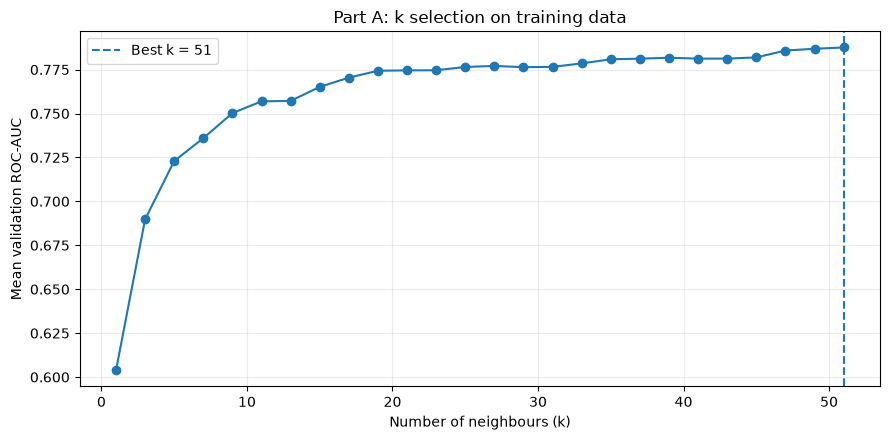

Best k in this search: 51
Best mean CV ROC-AUC: 0.7876
Interpretation: very small k has high variance and reacts to individual records; very large k has higher bias and smooths local differences. The best value is at the upper end of this search, so a wider follow-up search could be useful.


In [14]:
# Q14
cv_a = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
k_values_a = list(range(1, 52, 2))
mean_auc_a = []

for neighbour_count in k_values_a:
    candidate = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("knn", KNeighborsClassifier(n_neighbors=neighbour_count))
    ])
    fold_scores = cross_val_score(
        candidate, X_a_train[numeric_features_a], y_a_train,
        cv=cv_a, scoring="roc_auc", n_jobs=1
    )
    mean_auc_a.append(fold_scores.mean())

best_k_cv_a = k_values_a[int(np.argmax(mean_auc_a))]
plt.figure(figsize=(9, 4.5))
plt.plot(k_values_a, mean_auc_a, marker="o")
plt.axvline(best_k_cv_a, linestyle="--", label=f"Best k = {best_k_cv_a}")
plt.xlabel("Number of neighbours (k)")
plt.ylabel("Mean validation ROC-AUC")
plt.title("Part A: k selection on training data")
plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()
plt.show()

print(f"Best k in this search: {best_k_cv_a}")
print(f"Best mean CV ROC-AUC: {max(mean_auc_a):.4f}")
print("Interpretation: very small k has high variance and reacts to individual records; very large k has higher bias and smooths local differences. The best value is at the upper end of this search, so a wider follow-up search could be useful.")

### Q15 — One-hot encoding and GridSearchCV

Sex and family history are categorical inputs. The `ColumnTransformer` imputes and scales numeric data, imputes and one-hot encodes categories, and GridSearchCV tunes k, voting weights and the distance metric.

In [15]:
# Q15
a_preprocessor = ColumnTransformer([
    ("numeric", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), numeric_features_a),
    ("categorical", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]), categorical_features_a)
])

a_model_pipeline = Pipeline([
    ("preprocessor", a_preprocessor),
    ("knn", KNeighborsClassifier())
])

a_parameter_grid = {
    "knn__n_neighbors": k_values_a,
    "knn__weights": ["uniform", "distance"],
    "knn__p": [1, 2]
}
a_grid_search = GridSearchCV(
    a_model_pipeline,
    param_grid=a_parameter_grid,
    scoring="roc_auc",
    cv=cv_a,
    n_jobs=1
)
a_grid_search.fit(X_a_train, y_a_train)
best_model_a = a_grid_search.best_estimator_

print("Best settings:", a_grid_search.best_params_)
print(f"Best training CV ROC-AUC: {a_grid_search.best_score_:.4f}")
print("Interpretation: the best setting is selected using training folds; the test set remains untouched until evaluation.")

Best settings: {'knn__n_neighbors': 51, 'knn__p': 2, 'knn__weights': 'distance'}
Best training CV ROC-AUC: 0.7994
Interpretation: the best setting is selected using training folds; the test set remains untouched until evaluation.


### Q16 — Evaluate the tuned model at threshold 0.5

The default classifier threshold is used here. The confusion matrix is interpreted as a camp decision, not just a statistical count.

In [16]:
# Q16
tuned_predictions_a = best_model_a.predict(X_a_test)
tuned_probabilities_a = best_model_a.predict_proba(X_a_test)[:, 1]
tn_a, fp_a, fn_a, tp_a = confusion_matrix(y_a_test, tuned_predictions_a).ravel()

tuned_metrics_a = {
    "Accuracy": accuracy_score(y_a_test, tuned_predictions_a),
    "Precision": precision_score(y_a_test, tuned_predictions_a, zero_division=0),
    "Recall": recall_score(y_a_test, tuned_predictions_a, zero_division=0),
    "F1": f1_score(y_a_test, tuned_predictions_a, zero_division=0),
    "ROC-AUC": roc_auc_score(y_a_test, tuned_probabilities_a)
}
display(pd.DataFrame(tuned_metrics_a, index=["Tuned KNN"]).round(4))
print("Confusion matrix [ [TN, FP], [FN, TP] ]:")
print(np.array([[tn_a, fp_a], [fn_a, tp_a]]))
print(f"TN = {tn_a}: a visitor without a positive HbA1c result was correctly not sent for the test.")
print(f"FP = {fp_a}: a visitor without a positive result was sent for a test and used part of the grant.")
print(f"FN = {fn_a}: a visitor with a positive result was not sent for the test.")
print(f"TP = {tp_a}: a visitor with a positive result was correctly selected for the test.")
print("Interpretation: at 0.5 the model is conservative; the budget decision should use ranked probabilities rather than this default threshold.")

,Accuracy,Precision,Recall,F1,ROC-AUC
Tuned KNN,0.8027,0.775,0.1824,0.2952,0.8051


Confusion matrix [ [TN, FP], [FN, TP] ]:
[[571   9]
 [139  31]]
TN = 571: a visitor without a positive HbA1c result was correctly not sent for the test.
FP = 9: a visitor without a positive result was sent for a test and used part of the grant.
FN = 139: a visitor with a positive result was not sent for the test.
TP = 31: a visitor with a positive result was correctly selected for the test.
Interpretation: at 0.5 the model is conservative; the budget decision should use ranked probabilities rather than this default threshold.


### Q17 — Why Camp Location is not a predictor

**For inclusion:** location may capture differences in camp populations, local risk patterns or access to care.

**Against inclusion:** it can act as a proxy for neighbourhood or socioeconomic differences, and a model may learn location-specific patterns that do not transfer to a new camp. It is retained for reporting, not used for this first model.

### Q18 — Why the 0.5 threshold is not the budget rule

The grant funds exactly 250 tests, but a 0.5 threshold selects only the visitors whose estimated probability clears that cutoff. Accuracy rewards the many correctly classified negatives, while the operational objective is to rank the 750 visitors and use the fixed capacity on the highest-risk third.

In [17]:
# Q18
selected_at_half = tuned_probabilities_a >= 0.5
print(f"Tests selected at 0.5: {int(selected_at_half.sum())}")
print(f"Recall at 0.5: {recall_score(y_a_test, selected_at_half):.2%}")
print(f"Diabetics missed: {int(y_a_test.sum() - y_a_test.to_numpy()[selected_at_half].sum())}")
print("Interpretation: a high accuracy score does not make 0.5 a suitable cut-off when the programme has a fixed test budget.")

Tests selected at 0.5: 40
Recall at 0.5: 18.24%
Diabetics missed: 139
Interpretation: a high accuracy score does not make 0.5 a suitable cut-off when the programme has a fixed test budget.


### Q19 — Thresholds, test volume and cost

The hit-rate is the share of ordered tests that find a positive visitor. Cost per positive is the full test spend divided by the number of positive visitors found.

In [18]:
# Q19
threshold_rows_a = []
for probability_threshold in [0.1, 0.2, 0.3, 0.4, 0.5]:
    selected = tuned_probabilities_a >= probability_threshold
    tests_ordered = int(selected.sum())
    diabetics_found = int(y_a_test.to_numpy()[selected].sum())
    diabetics_missed = int(y_a_test.sum() - diabetics_found)
    hit_rate = diabetics_found / tests_ordered if tests_ordered else np.nan
    cost_per_positive = 450 * tests_ordered / diabetics_found if diabetics_found else np.nan
    threshold_rows_a.append({
        "Threshold": probability_threshold,
        "Tests ordered": tests_ordered,
        "Diabetics found": diabetics_found,
        "Diabetics missed": diabetics_missed,
        "Hit-rate": hit_rate,
        "Test cost per diabetic found (₹)": cost_per_positive
    })

threshold_table_a = pd.DataFrame(threshold_rows_a)
display(threshold_table_a.round({
    "Hit-rate": 3, "Test cost per diabetic found (₹)": 2
}))
print("Interpretation: lowering the threshold finds more positive visitors but increases the number and total cost of tests.")

,Threshold,Tests ordered,Diabetics found,Diabetics missed,Hit-rate,Test cost per diabetic found (₹)
0,0.1,523,158,12,0.302,1489.56
1,0.2,332,135,35,0.407,1106.67
2,0.3,188,96,74,0.511,881.25
3,0.4,99,57,113,0.576,781.58
4,0.5,40,31,139,0.775,580.65


Interpretation: lowering the threshold finds more positive visitors but increases the number and total cost of tests.


### Q20 — Use the full 250-test budget

Rank the test set by the tuned model's probability and select exactly the highest 250 scores.

In [19]:
# Q20
ranked_test_positions_a = np.argsort(-tuned_probabilities_a, kind="stable")
top_250_positions_a = ranked_test_positions_a[:250]
top_250_found_a = int(y_a_test.to_numpy()[top_250_positions_a].sum())
total_positive_test_a = int(y_a_test.sum())
random_expected_a = 250 * y_a_test.mean()

print(f"Tests used: {len(top_250_positions_a)}")
print(f"Diabetics found: {top_250_found_a} out of {total_positive_test_a} in the test set")
print(f"Random-selection expectation: {random_expected_a:.1f} (about {round(random_expected_a)})")
print(f"Additional positives over random expectation: {top_250_found_a - random_expected_a:.1f}")
print(f"Cost of 250 tests: ₹{250 * 450:,.0f}")
print("Interpretation: probability ranking is evaluated against the same 750 visitors and the same 250-test capacity as random selection.")

Tests used: 250
Diabetics found: 117 out of 170 in the test set
Random-selection expectation: 56.7 (about 57)
Additional positives over random expectation: 60.3
Cost of 250 tests: ₹112,500
Interpretation: probability ranking is evaluated against the same 750 visitors and the same 250-test capacity as random selection.


### Q21 — Compare with the current age-and-waist rule

The current rule selects visitors aged at least 45, with waist at least 90 cm for men or 80 cm for women. It is applied to the same test set.

In [20]:
# Q21
test_patients_a = a_clean.loc[X_a_test.index].copy()
waist_cutoff_a = np.where(test_patients_a["sex"].eq("Male"), 90, 80)
eyeball_selection_a = (
    test_patients_a["age"].ge(45)
    & test_patients_a["waist_cm"].ge(waist_cutoff_a)
)
eyeball_tests_a = int(eyeball_selection_a.sum())
eyeball_found_a = int(test_patients_a.loc[eyeball_selection_a, "hba1c_result"].sum())

top250_cost_per_positive_a = 250 * 450 / top_250_found_a
eyeball_cost_per_positive_a = 450 * eyeball_tests_a / eyeball_found_a

comparison_budget_a = pd.DataFrame([
    {
        "Rule": "Top 250 by KNN probability",
        "Tests": 250,
        "Diabetics found": top_250_found_a,
        "Cost (₹)": 250 * 450,
        "Cost per diabetic found (₹)": top250_cost_per_positive_a
    },
    {
        "Rule": "Age + waist rule",
        "Tests": eyeball_tests_a,
        "Diabetics found": eyeball_found_a,
        "Cost (₹)": eyeball_tests_a * 450,
        "Cost per diabetic found (₹)": eyeball_cost_per_positive_a
    }
])
display(comparison_budget_a.round(2))
print("Interpretation: the KNN ranking uses the grant limit and finds almost as many positives as the broader eyeball rule, with fewer tests.")

,Rule,Tests,Diabetics found,Cost (₹),Cost per diabetic found (₹)
0,Top 250 by KNN probability,250,117,112500,961.54
1,Age + waist rule,350,118,157500,1334.75


Interpretation: the KNN ranking uses the grant limit and finds almost as many positives as the broader eyeball rule, with fewer tests.


### Q22 — Explain one selected visitor using actual neighbours

The highest-ranked visitor is selected from the top 250. The tuned model's preprocessor transforms both this visitor and the training set; the five closest training records are then retrieved from the fitted KNN estimator.

In [21]:
# Q22
chosen_test_position_a = int(top_250_positions_a[0])
chosen_test_index_a = X_a_test.index[chosen_test_position_a]
chosen_visitor_a = X_a_test.loc[[chosen_test_index_a]]
chosen_probability_a = float(tuned_probabilities_a[chosen_test_position_a])
chosen_rank_a = 1

fitted_preprocessor_a = best_model_a.named_steps["preprocessor"]
fitted_knn_a = best_model_a.named_steps["knn"]
transformed_train_a = fitted_preprocessor_a.transform(X_a_train)
transformed_visitor_a = fitted_preprocessor_a.transform(chosen_visitor_a)
neighbour_count_a = fitted_knn_a.n_neighbors
neighbour_distances_a, neighbour_positions_a = fitted_knn_a.kneighbors(
    transformed_visitor_a, n_neighbors=neighbour_count_a
)
neighbour_indices_a = X_a_train.index[neighbour_positions_a[0]]
neighbours_a = a_clean.loc[neighbour_indices_a, [
    "patient_id", "age", "sex", "family_history", "bmi",
    "waist_cm", "daily_steps", "systolic", "diastolic", "hba1c_result"
]].copy()
neighbours_a.insert(0, "distance", neighbour_distances_a[0])

print(f"Selected visitor: {a_clean.loc[chosen_test_index_a, 'patient_id']}")
print(f"Rank: {chosen_rank_a} of 750; estimated positive probability: {chosen_probability_a:.3f}")
display(a_clean.loc[[chosen_test_index_a], [
    "patient_id", "age", "sex", "family_history", "bmi",
    "waist_cm", "daily_steps", "hba1c_result"
]])
print("Nearest training visitors:")
display(neighbours_a)
positive_neighbours_a = int((neighbours_a["hba1c_result"] == 1).sum())
print(f"The fitted model uses {neighbour_count_a} neighbours; {positive_neighbours_a} of them had a positive HbA1c result.")
print(f"Volunteer explanation: Your measurements are close to people in last year's pilot group who had a positive HbA1c result; {positive_neighbours_a} of the {neighbour_count_a} neighbours used by the model were positive. This is why you are being offered one of today's funded tests; the score helps prioritise screening and is not a diagnosis.")
print("Interpretation: the explanation is grounded in the visitor's nearest historical cases; it does not present KNN as a diagnosis.")

Selected visitor: SD-22042
Rank: 1 of 750; estimated positive probability: 0.753


,patient_id,age,sex,family_history,bmi,waist_cm,daily_steps,hba1c_result
2960,SD-22042,63.0,Male,1,35.3,102.0,4300.0,1


Nearest training visitors:


,distance,patient_id,age,sex,family_history,bmi,waist_cm,daily_steps,systolic,diastolic,hba1c_result
2247,1.737447,SD-21681,56.0,Female,1,34.000000,101.0,4460.0,151.0,96.0,0
1003,2.259137,SD-20825,70.0,Female,1,34.254974,105.0,8360.0,148.0,88.0,1
214,2.277078,SD-21725,60.0,Male,1,27.548675,99.0,5420.0,138.0,97.0,0
2529,2.316260,SD-20651,49.0,Male,1,32.200000,102.0,5640.0,132.0,93.0,0
2497,2.325499,SD-20873,59.0,Male,0,28.700000,103.0,3790.0,145.0,94.0,1
1376,2.342033,SD-22006,60.0,Male,0,34.000000,NaN,6970.0,148.0,93.0,1
1368,2.344190,SD-20798,64.0,Female,1,30.400000,98.0,4300.0,156.0,110.0,1
2782,2.345251,SD-21929,43.0,Male,0,35.200000,104.0,4050.0,145.0,93.0,0
2439,2.376255,SD-20819,52.0,Female,1,32.900000,93.0,6250.0,144.0,98.0,1
1620,2.378546,SD-22510,56.0,Male,0,30.100000,112.0,5020.0,148.0,97.0,0


The fitted model uses 51 neighbours; 39 of them had a positive HbA1c result.
Volunteer explanation: Your measurements are close to people in last year's pilot group who had a positive HbA1c result; 39 of the 51 neighbours used by the model were positive. This is why you are being offered one of today's funded tests; the score helps prioritise screening and is not a diagnosis.
Interpretation: the explanation is grounded in the visitor's nearest historical cases; it does not present KNN as a diagnosis.


### Q23 — Reply to the visitor ranked 260th

“Weight is only one of the measurements used by the model. It compares the overall pattern, including age, BMI, waist, activity, blood pressure, cholesterol, sex and family history; your friend may have been closer to more positive cases on that combined pattern. The camp has 250 funded tests, so we selected the 250 highest scores, and a rank of 260 means the score fell just below today's capacity line. It does not mean that your risk is zero or that the model has diagnosed either of you.”

### Q24 — Compare raw, scaled and tuned models

The top-250 result is computed from probability rankings on the same held-out test set for each model.

In [22]:
# Q24
def top_250_positive_count(model, features, target):
    probabilities = model.predict_proba(features)[:, 1]
    selected_positions = np.argsort(-probabilities, kind="stable")[:250]
    return int(target.to_numpy()[selected_positions].sum())

summary_a = pd.DataFrame([
    {
        "Model": "Raw KNN (k=5)",
        **{key: raw_metrics_a[key] for key in ["Accuracy", "Recall", "ROC-AUC"]},
        "Diabetics in top 250": top_250_positive_count(raw_knn_a, X_a_test[numeric_features_a], y_a_test)
    },
    {
        "Model": "Scaled KNN (k=5)",
        **{key: scaled_metrics_a[key] for key in ["Accuracy", "Recall", "ROC-AUC"]},
        "Diabetics in top 250": top_250_positive_count(scaled_knn_a, X_a_test[numeric_features_a], y_a_test)
    },
    {
        "Model": "Tuned KNN",
        **{key: tuned_metrics_a[key] for key in ["Accuracy", "Recall", "ROC-AUC"]},
        "Diabetics in top 250": top_250_found_a
    }
]).set_index("Model")
display(summary_a.round(4))
print("Interpretation: scaling improves ranking quality, and adding categorical data plus tuning produces the strongest top-250 result.")

,Accuracy,Recall,ROC-AUC,Diabetics in top 250
Model,,,,
Raw KNN (k=5),0.7627,0.1765,0.6564,81
Scaled KNN (k=5),0.7880,0.3412,0.7223,99
Tuned KNN,0.8027,0.1824,0.8051,117


Interpretation: scaling improves ranking quality, and adding categorical data plus tuning produces the strongest top-250 result.


### Q25 — Recommendation to the CSR programme manager

Use the tuned KNN as a **screening-priority aid**, not as a diagnostic decision or a replacement for clinical judgement. On this held-out group, ranking the 750 visitors and testing the top 250 finds **117 positive cases**, compared with about **57** expected from random selection, or roughly **60 more positives per 250 tests**. Volunteers would enter the free measurements, review the ranked list and invite the highest-ranked visitors for HbA1c until the 250 funded slots are used. The model also finds 117 positives with 250 tests, while the current age-and-waist rule needs 350 tests to find 118, so the ranking uses the grant more efficiently. The main risk is that the pilot represents people who attended last year's camps; groups who did not attend, or whose measurements and risk patterns differ from the pilot population, may be ranked less reliably. The programme should monitor results by camp and demographic group and re-check performance on new HbA1c-confirmed visitors before relying on the ranking at scale.